# EMCEE Algorithm for Four paramters Hubble Data

In [ ]:
#Required Hubble data
import numpy as np
z=np.array([0.07  , 0.09  , 0.12  , 0.17  , 0.179 , 0.199 , 0.2   , 0.27  ,
       0.28  , 0.352 , 0.3802, 0.4   , 0.4004, 0.4247, 0.4497, 0.47  ,
       0.4783, 0.48  , 0.5929, 0.6797, 0.7812, 0.8754, 0.88  , 0.9   ,
       1.037 , 1.3   , 1.363 , 1.43  , 1.53  , 1.75  , 1.965 ]);                      #Redshift
hz= np.array([ 69. ,  69. ,  68.6,  83. ,  75. ,  75. ,  72.9,  77. ,  88.8,
        83. ,  83. ,  95. ,  77. ,  87.1,  92.8,  89. ,  80.9,  97. ,
       104. ,  92. , 105. , 125. ,  90. , 117. , 154. , 168. , 160. ,
       177. , 140. , 202. , 186.5])                                                   #Hubble Parmater
shz=np.array([19.6, 12. , 26.2,  8. ,  4. ,  5. , 29.6, 14. , 36.6, 14. , 13.5,
       17. , 10.2, 11.2, 12.9, 34. ,  9. , 62. , 13. ,  8. , 12. , 17. ,
       40. , 23. , 20. , 17. , 33.6, 18. , 14. , 40. , 50.4])                         #Errors

In [ ]:
!pip install -U emcee
!pip install -U corner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.4/47.4 kB 3.1 MB/s eta 0:00:00


In [ ]:
import numpy as np
#Likelihood from Hubble Parameter
def log_likelihood(om, ov, ok, h0):
  n=len(z)
  sum=0
  for i in range(0,n):
    sum= sum+ (hz[i]-h0*(om*(1+z[i])**3+ok*(1+z[i])**2+ov)**0.5)**2/(shz[i])**2
  return -0.5*(sum)

#Prior Information
def log_prior(om, ov, ok, h0):
  h0prior= -(h0-70)**2/(2*3**2)
  omprior= -(om-0.3)**2/(2*0.1**2)
  ovprior= -(ov-0.7)**2/(2*0.1**2)
  if -1<ok<1:
    okprior=0.0
  else:
    okprior=-np.inf
  net= h0prior+omprior+ovprior+okprior
  return net

#Log of Posterior
def log_posterior1(theta):
  om, ov, ok, h0= theta
  lp=log_prior(om, ov, ok, h0)
  func= log_likelihood(om, ov, ok, h0)+ log_prior(om, ov, ok, h0)
  return func

In [ ]:
#Finding best initial Guess by minimizing the function

import scipy.optimize as optimize

def chi2(theta):
    om, ov, ok, h0 = theta
    prior=log_prior(om,ov,ok,h0)
    chi= -2 * log_posterior1(theta)
    return chi

initial_guess = [0.3, 0.7, 0, 70]
result = optimize.minimize(chi2, initial_guess,method='nelder-mead',
                     options={'maxiter':10000,'xtol': 1e-8, 'disp': True})
if result.success:
    fitted_params = result.x
    print(fitted_params)
else:
    raise ValueError(result.message)

Optimization terminated successfully.
         Current function value: 14.514260
         Iterations: 229
         Function evaluations: 385
[ 3.16801387e-01  6.94473262e-01 -4.72422062e-02  7.00381126e+01]


/tmp/ipython-input-16-315803273.py:12: OptimizeWarning: Unknown solver options: xtol
  result = optimize.minimize(chi2, initial_guess,method='nelder-mead',


In [ ]:
#Taking Different Initial Guesses for different Walkers

ndimension=4
no_of_walkers=10
no_of_steps_per_walker= 10000
burn_in_steps=100

initial_pos_of_walker = [result["x"] + 1e-3*np.random.randn(ndimension) for i in range(no_of_walkers)]
print(initial_pos_of_walker)

[array([ 3.14993450e-01,  6.94992059e-01, -4.72639014e-02,  7.00386528e+01]), array([ 3.16963287e-01,  6.94813974e-01, -4.80867172e-02,  7.00390878e+01]), array([ 3.14152186e-01,  6.94417052e-01, -4.75887589e-02,  7.00373844e+01]), array([ 3.16475392e-01,  6.94217343e-01, -4.70694765e-02,  7.00382439e+01]), array([ 3.16542422e-01,  6.93661638e-01, -4.85618810e-02,  7.00377295e+01]), array([ 3.18911841e-01,  6.94177976e-01, -4.81920991e-02,  7.00373451e+01]), array([ 3.14629651e-01,  6.95828049e-01, -4.70934292e-02,  7.00405649e+01]), array([ 3.16177269e-01,  6.94376091e-01, -4.79609481e-02,  7.00385982e+01]), array([ 3.15901175e-01,  6.94498639e-01, -4.84452247e-02,  7.00381395e+01]), array([ 3.16489443e-01,  6.95481819e-01, -4.84141206e-02,  7.00383117e+01])]


In [ ]:
#Running EMCEE Algorithm through its Library

import emcee
sampler = emcee.EnsembleSampler(no_of_walkers, ndimension, log_posterior1, a=3)
sampler.run_mcmc(initial_pos_of_walker, no_of_steps_per_walker, rstate0=np.random.get_state(),progress=True);

100%|██████████| 10000/10000 [00:12<00:00, 790.08it/s]


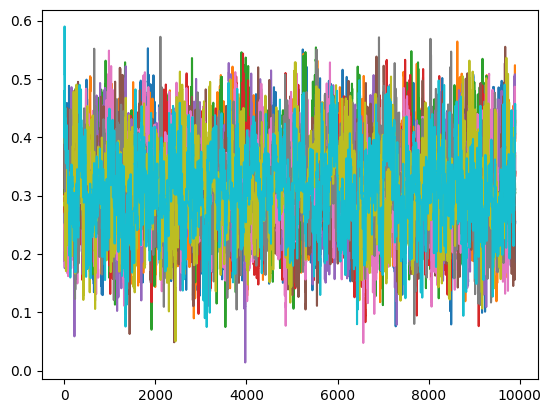

In [ ]:
#Plotting chains for value of 'Omega_m'
import matplotlib.pyplot as plt
for i in range(0,no_of_walkers):
  a=sampler.chain[i,burn_in_steps:,0]
  l=len(a)
  n= list(range(l))
  plt.plot(n,a)

plt.show()

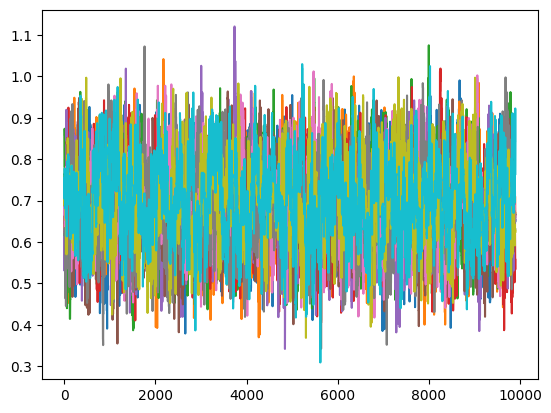

In [ ]:
#Plotting chains for value of 'Omega_lambda'
for i in range(0,no_of_walkers):
  b=sampler.chain[i,burn_in_steps:,1]
  l=len(b)
  n= list(range(l))
  plt.plot(n,b)

plt.show()

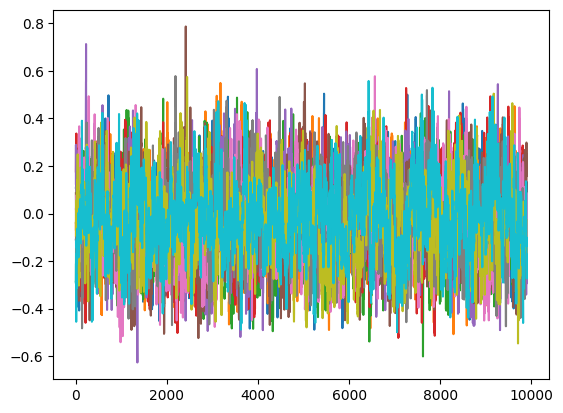

In [ ]:
#Plotting chains for value of 'H_0'
for i in range(0,no_of_walkers):
  c=sampler.chain[i,burn_in_steps:,2]
  l=len(c)
  n= list(range(l))
  plt.plot(n,c)

plt.show()

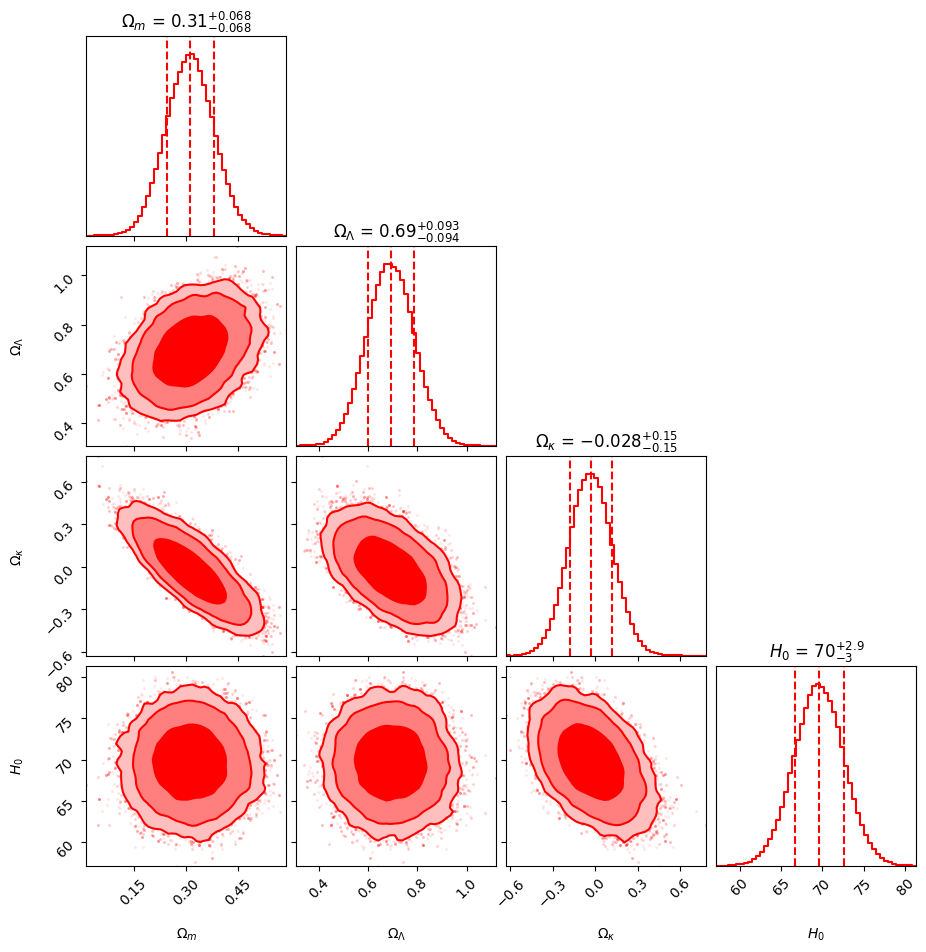

In [ ]:
#Histogram and contour plots
import corner
samples = sampler.chain[:, burn_in_steps:, :].reshape((-1, ndimension))
fig = corner.corner(samples,bins=50,labels=["$\Omega_m$", "$\Omega_{\Lambda}$","$\Omega_{\kappa}$","$H_0$"],
                    color="red",
                    quantiles=[0.16, 0.5, 0.84],                    #68% Confidence Error in Histogram
                    plot_contours=True,
                    fill_contours=True,
                    levels=(0.68,0.95,0.99),                        #Confidence Levels
                    plot_datapoints=True,
                    smooth=True, smooth1d=True,
                    title_fmt=".2g",
                    show_titles=True,
                    divergences=True)

plt.show()